In [1]:
import time
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field
from Cmax import ContrastMaximizationLoss

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from utils.metrics import PIVmetric

# 检查CUDA是否可用
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

CUDA acceleration: OK
cuda


In [2]:
max_v = 5

flow0 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")
flow1 = FlowManager(mode="data", data_path="./data/datasets/DNS_turbulence_00001_flow.npz")
flow2 = FlowManager(mode="data", data_path="./data/datasets/SQG_00001_flow.npz")

flow3 = FlowManager(mode="analytical", name="cellular_flow", vmax=max_v, p=256)
flow4 = FlowManager(mode="analytical", name="lamb_oseen", x_c=128, y_c=128, Gamma=3e3, rc=60)
flow5 = FlowManager(mode="analytical", name="shear_flow", vmax=max_v, p=256)

flow6 = FlowManager(mode="data", data_path="./data/datasets/backstep_Re1500_00001_flow.npz")

flow7 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_mhd1024_hd_00001_flow.npz")
flow8 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_channel_hd_00001_flow.npz")

flow9 = FlowManager(mode="analytical", name="gs_flow", max_v=5.0, n_vortex=20, seed=1)
flow10 = FlowManager(mode="analytical", name="solid_rot", x_c=128, y_c=128, omega=0.005525*max_v)
flow11 = FlowManager(mode="analytical", name="uniform", uc=max_v/np.sqrt(2), vc=max_v/np.sqrt(2))
flow12 = FlowManager(mode="analytical", name="sin_flow", x_c=128,y_c=128, a=16, b=128, scale=max_v)
flow13 = FlowManager(mode="data", data_path="./data/datasets/cylinder_Re150_00001_flow.npz")

In [23]:
from gaussian_flow import GaussianFlowConfig, run_gaussian_flow, train_gaussian_flow, render_gaussian_flow
# from profile_cuda_train import profile_train_timing_cuda

for flow_index in range(1):
    
    flow_name = f"flow{flow_index}"
    flow_func = globals()[flow_name].evaluate

    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)

    evts, (u, v) = event_loader.load()
    flowgt = torch.stack([u, v], dim=0).to(device)

    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]

    h_gt = u.cpu().numpy()
    w_gt = v.cpu().numpy()

    # cfg = GaussianFlowConfig(verbose=True, init_n=200, enable_jacobian=True, phase=[50, 100, 125], tile_size = 32, 
    #                          iterations=150, density_interval=25, cmax_sigma= 0.6, cmax_kernel_size = 5,
    #                         cmax_loss_type= 'l2_max', w_div = 5, density_alpha = 0, w_smooth = 0.0)

    cfg = GaussianFlowConfig(verbose=False, iterations=300, init_n=200, enable_jacobian=True,
                             w_div = 5, w_smooth = 0, cmax_loss_type= 'l2_max', phase=[50, 200, 250],
                             cmax_sigma= 0.6, cmax_kernel_size = 5)

    torch.cuda.synchronize()
    start_time = time.time()
    res = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
    torch.cuda.synchronize()
    end_time = time.time()
    print(f"总时间：{end_time - start_time:.4f}")

    # report = profile_train_timing_cuda(events=events, cfg=cfg, flowgt=None, warmup=10, profile_steps=100, include_density_control=True, print_every=10)

    pred_h, pred_w = res.flow[0], res.flow[1]
    PIVmetric(pred_h, pred_w, h_gt, w_gt, show=True)[:2]

    torch.cuda.empty_cache()

总时间：1.4315
0.2648(RMSE)	0.2084(AEE)	0.1281(AAE,rad)	0.8501(SSIM)	0.9843(MoC)	231(epe1)	0(epe2)	0(epe3)	


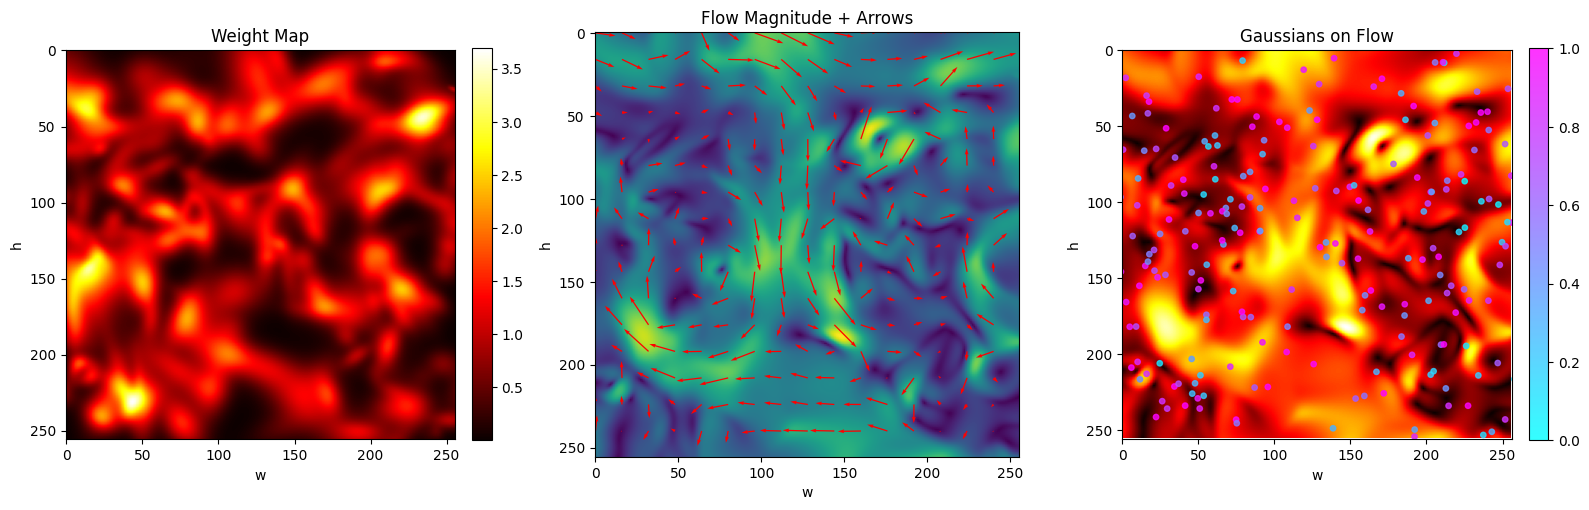

In [22]:
def visualize_coherence_hw(model, pred_flow, weight_map, events=None, arrow_step=16, quiver_scale=50):

    H, W = model.H, model.W

    with torch.no_grad():
        flow = pred_flow.detach().cpu()                    # [2, H, W]
        wmap = weight_map.squeeze().detach().cpu()         # [H, W]

        v_h = flow[0]                                      # [H, W] 竖直分量
        v_w = flow[1]                                      # [H, W] 水平分量
        flow_mag = torch.sqrt(v_h**2 + v_w**2)            # [H, W]

        # 归一化用于背景显示
        flow_mag_norm = (flow_mag - flow_mag.min()) / (flow_mag.max() - flow_mag.min() + 1e-6)

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))

        ax = axes[0]
        im = ax.imshow(wmap.numpy(), cmap='hot')
        ax.set_title('Weight Map')
        ax.set_xlabel('w')
        ax.set_ylabel('h')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        ax = axes[1]
        ax.imshow(flow_mag.numpy(), cmap='viridis')

        h_coords = torch.arange(0, H, arrow_step)
        w_coords = torch.arange(0, W, arrow_step)
        hh, ww = torch.meshgrid(h_coords, w_coords, indexing='ij')
        
        u = v_w[hh, ww].numpy()
        v = v_h[hh, ww].numpy()

        ax.quiver(
            ww.numpy(), hh.numpy(),
            u, -v,
            scale=quiver_scale,
            color='red',
            width=0.003
        )
        ax.set_title('Flow Magnitude + Arrows')
        ax.set_xlabel('w')
        ax.set_ylabel('h')

        ax = axes[2]
        ax.imshow(flow_mag_norm.numpy(), cmap='hot')

        mu_np = model.mu.detach().cpu().numpy()   # [N, 2], [h, w]
        op_np = torch.sigmoid(model.opacity_logit).squeeze().detach().cpu().numpy()

        sc = ax.scatter(
            mu_np[:, 1],   # w
            mu_np[:, 0],   # h
            c=op_np,
            cmap='cool',
            s=15,
            alpha=0.8,
            vmin=0,
            vmax=1
        )
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title('Gaussians on Flow')
        ax.set_xlabel('w')
        ax.set_ylabel('h')
        ax.set_xlim(0, W)
        ax.set_ylim(H, 0)

        plt.tight_layout()
        plt.show()

visualize_coherence_hw(res.model, torch.tensor(res.flow), res.weight_map, events=events, arrow_step=16, quiver_scale=50)

In [ ]:
def analyze_model_stats(model):
    """
    全面分析训练后 GaussianVelocityField 模型的各项参数统计信息
    """
    print("="*60)
    print(f"MODEL STATISTICS REPORT (N={model.num_gaussians})")
    print("="*60)
    
    # 将数据移回 CPU 并转为 NumPy
    with torch.no_grad():
        mu = model.mu.detach().cpu().numpy()
        log_scale = model.log_scale.detach().cpu().numpy()
        scales = np.exp(log_scale)
        rotation = model.rotation.detach().cpu().numpy()
        opacity = torch.sigmoid(model.opacity_logit).detach().cpu().numpy()
        velocity = model.local_velocity.detach().cpu().numpy()
        J = model.J_params.detach().cpu().numpy()

    # --- 1. 位置 (Position) ---
    print(f"\n[1. Position (mu)]")
    print(f"  Range X: {mu[:, 1].min():.2f} ~ {mu[:, 1].max():.2f}")
    print(f"  Range Y: {mu[:, 0].min():.2f} ~ {mu[:, 0].max():.2f}")
    # 检查有多少跑出画布外
    out_bound = ((mu[:,0]<0)|(mu[:,0]>model.H)|(mu[:,1]<0)|(mu[:,1]>model.W)).sum()
    print(f"  Out of bounds: {out_bound} / {model.num_gaussians} ({out_bound/model.num_gaussians*100:.1f}%)")

    # --- 2. 尺度 (Scale) ---
    print(f"\n[2. Scale (pixels)]")
    print(f"  Min: {scales.min():.4f} | Max: {scales.max():.4f}")
    print(f"  Mean: {scales.mean():.4f} | Median: {np.median(scales):.4f}")
    
    # 长宽比 (Anisotropy)
    aspect_ratios = np.max(scales, axis=1) / np.min(scales, axis=1)
    print(f"  Aspect Ratio (Long/Short): Mean={aspect_ratios.mean():.2f}, Max={aspect_ratios.max():.2f}, Median={np.median(aspect_ratios):.2f}")
    if aspect_ratios.max() > 10:
        print("  WARNING: 存在极度细长的高斯，可能导致渲染伪影。")

    # --- 3. 不透明度 (Opacity) ---
    print(f"\n[3. Opacity (alpha)]")
    print(f"  Mean: {opacity.mean():.4f}")
    print(f"  < 0.1 (Transparent): {(opacity < 0.1).sum()} count")
    print(f"  > 0.9 (Solid):       {(opacity > 0.9).sum()} count")
    # 理想情况下，opacity 应该是两极分化的（要么很有用，要么没用）

    # --- 4. 速度 (Velocity) ---
    vel_mag = np.linalg.norm(velocity, axis=1)
    print(f"\n[4. Velocity Magnitude]")
    print(f"  Mean: {vel_mag.mean():.4f} | Max: {vel_mag.max():.4f}")
    print(f"  Min:  {vel_mag.min():.4f}")

    # --- 5. 雅可比 (Jacobian) ---
    J_mag = np.linalg.norm(J, axis=1) # Frobenius norm
    print(f"\n[5. Jacobian Norm]")
    print(f"  Mean: {J_mag.mean():.4f} | Max: {J_mag.max():.4f}")

    print("="*60)
    
    # ==========================================
    # 可视化绘图
    # ==========================================
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(f'Model Parameter Analysis (N={model.num_gaussians})', fontsize=16)

    # Plot 1: 空间分布散点图
    ax = axes[0, 0]
    ax.set_title("Gaussian Centers (Spatial)")
    # 根据 Opacity 设置颜色深浅
    mask = np.max(scales, axis=1) < 1
    mu_m = mu[mask]
    print(mu_m.shape)
    opacity_m = opacity[mask]
    sc = ax.scatter(mu_m[:, 1], mu_m[:, 0], c=opacity_m, cmap='viridis', s=10, alpha=0.7)
    ax.set_xlim(0, model.W)
    ax.set_ylim(0, model.H)
    ax.invert_yaxis() # 图像坐标系 Y 轴向下
    plt.colorbar(sc, ax=ax, label='Opacity')

    # Plot 2: 尺度分布 (直方图)
    ax = axes[0, 1]
    scales_mask = scales.flatten()[scales.flatten() < 2000]
    ax.set_title("Scale Distribution (Pixels)")
    ax.hist(scales_mask, bins=30, color='skyblue', edgecolor='black')
    ax.set_xlabel("Scale Value")

    # Plot 3: 长宽比分布
    ax = axes[0, 2]
    aspect_ratios = aspect_ratios[aspect_ratios < 10]
    ax.set_title("Aspect Ratio (Anisotropy)")
    ax.hist(aspect_ratios, bins=30, color='salmon', edgecolor='black')
    ax.set_xlabel("Long / Short Axis")

    # Plot 4: 不透明度分布
    ax = axes[1, 0]
    ax.set_title("Opacity Distribution")
    ax.hist(opacity.flatten(), bins=20, range=(0,1), color='lightgreen', edgecolor='black')
    ax.set_xlabel("Alpha (0~1)")
    ax.set_yscale('log') # 使用对数坐标，因为通常 0 附近的数量极大

    # Plot 5: 速度幅度分布
    ax = axes[1, 1]
    ax.set_title("Local Velocity Magnitude")
    ax.hist(vel_mag, bins=30, color='orange', edgecolor='black')
    ax.set_xlabel("Speed")

    # Plot 6: 旋转角度分布
    ax = axes[1, 2]
    # ax.set_title("Rotation (Degrees)")
    # # 将弧度转为度，并映射到 0-180 (因为椭圆旋转具有对称性)
    # deg = (np.degrees(rotation) % 180).flatten()
    # ax.hist(deg, bins=36, range=(0, 180), color='purple', edgecolor='black')
    # ax.set_xlabel("Angle (0-180)")
    J_mask = J.flatten()[J.flatten() < 20]
    ax.set_title("J Distribution (Pixels)")
    ax.hist(J_mask, bins=50, color='skyblue', edgecolor='black')
    ax.set_xlabel("Scale Value")

    plt.tight_layout()
    plt.show()

# 使用方法：
analyze_model_stats(res.model)